# hengck23's original Stage 0 + Stage 1, run locally

The **Stage 0 and Stage 1 cells below are copied unchanged** from hengck23's Kaggle notebook
(`reference/hengck23-demo-submission/demo-submission.ipynb`, cells 2-3). Only his setup cells (0-1) are replaced,
because they point at Kaggle-only paths (`/kaggle/input/...`) and a GPU.

What to watch:
* **The call sequence.** Stage 0: `image_to_batch` → `stage0_net` → `output_to_predict` → `normalise_by_homography`.
  Stage 1: `stage1_net` → `output_to_predict` → `rectify_image`.
* **The hand-off between stages through files.** Stage 0 writes `{id}.norm.png` (+ the homography `.homo.npy`),
  and Stage 1 reads that file back and writes `{id}.rect.png` (+ the grid corners `.gridpoint_xy.npy`).
* **`FAIL_ID`.** Any image where a step throws an error is recorded and skipped by later stages.

Runs on CPU in about 1 minute per image. His `autocast('cuda')` is automatically disabled on a machine without
CUDA (you will see a warning), so everything runs in fp32.

In [1]:
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg")

In [2]:
# ---- LOCAL replacement for hengck23's cells 0-1 (Kaggle paths -> this repo) ----
import os, sys, shutil
from pathlib import Path
if not Path('train.py').exists():   # run from the repo root
    os.chdir('..')

import cc3d
import cv2
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append('reference/hengck23-demo-submit-physionet')   # was /kaggle/input/hengck23-demo-submit-physionet

MODE   = 'local'
DEVICE = 'cpu'                     # was 'cuda'
FLOAT_TYPE = torch.float16         # unused on CPU: autocast('cuda') disables itself
FAIL_ID = []

KAGGLE_DIR = 'data/competition'                               # our downloaded originals (train/{id}/{id}-{type}.png)
WEIGHT_DIR = 'reference/hengck23-demo-submit-physionet/weight'
OUT_DIR    = 'outputs/hengck23-local'                         # gitignored

valid_df = pd.read_csv(f'{KAGGLE_DIR}/train.csv')
valid_df['id'] = valid_df['id'].astype(str)

# a few hard captures of one record: carpet photo, monitor photo, stained paper
valid_id = ['3056263433-0005', '3056263433-0006', '3056263433-0009']

def read_image(sample_id):          # his 'local' branch
    image_id, type_id = sample_id.split('-')
    return cv2.imread(f'{KAGGLE_DIR}/train/{image_id}/{image_id}-{type_id}.png', cv2.IMREAD_COLOR_RGB)

print('valid_id:', valid_id)
print('setting ok!!!')

valid_id: ['3056263433-0005', '3056263433-0006', '3056263433-0009']
setting ok!!!


## Stage 0 (hengck23's cell 2, unchanged)

*** STARTING STAGE0 ***
THIS_DIR: c:\Users\darre\Documents\Kaggle\Assignment_1_ECG_ML\reference\hengck23-demo-submit-physionet
REF_PT: (9, 2)
<All keys matched successfully>
	    0 3056263433-0005  0 min 00 sec

C:\Users\darre\AppData\Local\Temp\ipykernel_45048\1357113489.py:22: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.amp.autocast('cuda', dtype=FLOAT_TYPE):



demo results for stage0--------------
3056263433-0005


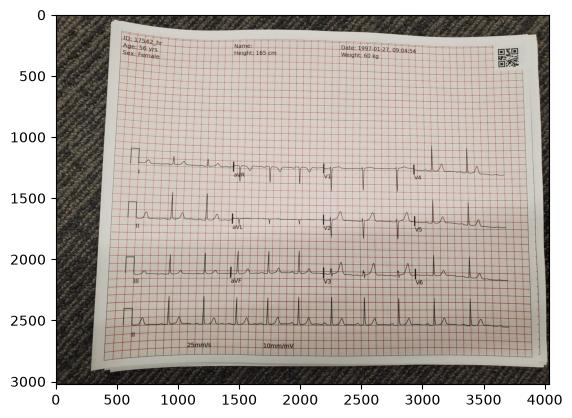

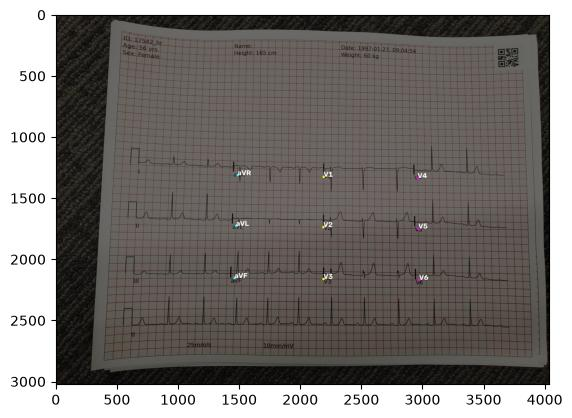

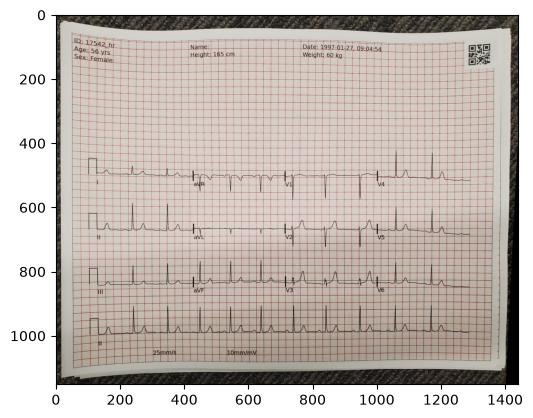

	    1 3056263433-0006  2 min 31 sec

C:\Users\darre\AppData\Local\Temp\ipykernel_45048\1357113489.py:22: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.amp.autocast('cuda', dtype=FLOAT_TYPE):



demo results for stage0--------------
3056263433-0006


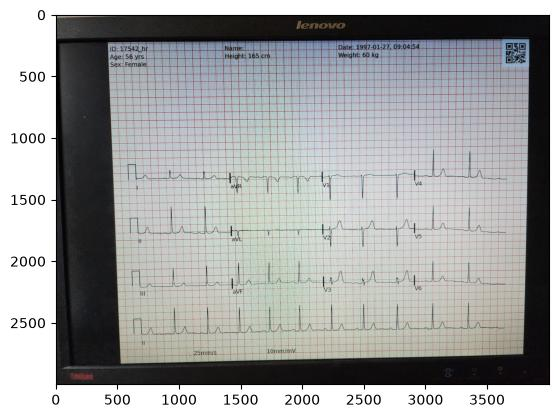

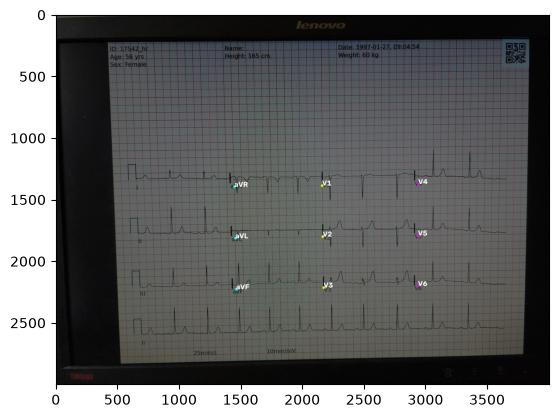

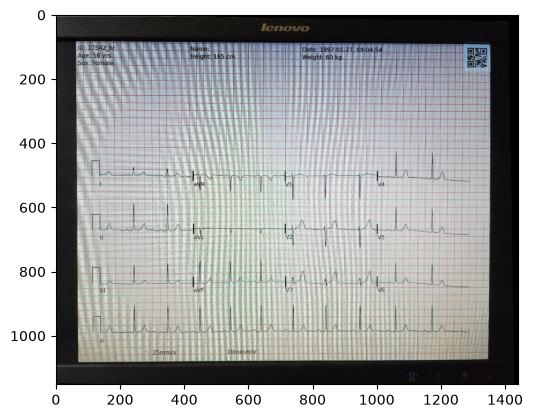

	    2 3056263433-0009  5 min 30 sec

C:\Users\darre\AppData\Local\Temp\ipykernel_45048\1357113489.py:22: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.amp.autocast('cuda', dtype=FLOAT_TYPE):



demo results for stage0--------------
3056263433-0009


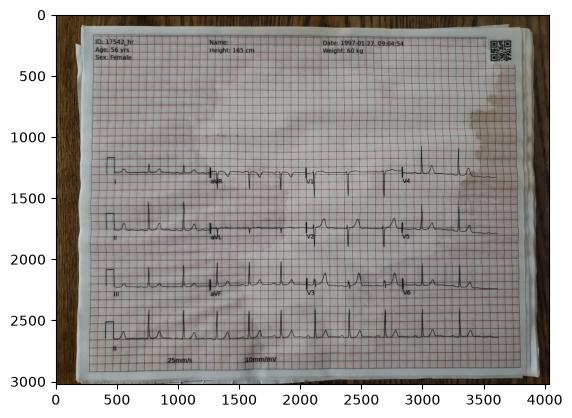

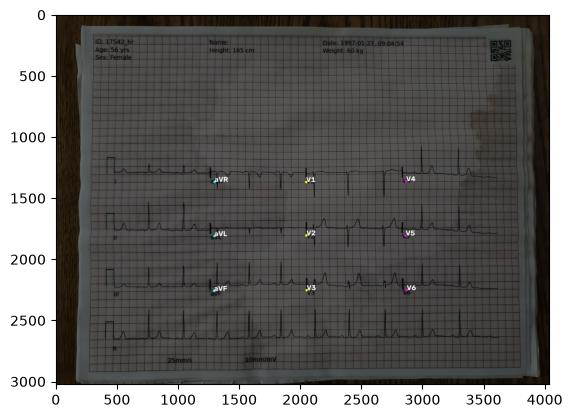

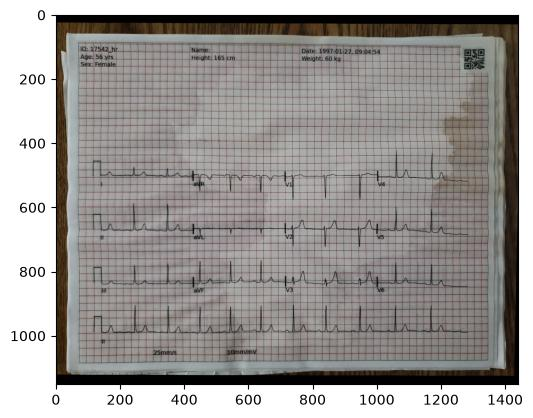


FAIL_ID: []
run_stage0() ok!!!



In [3]:
# stage0
print('*** STARTING STAGE0 ***')

from stage0_model import Net as Stage0Net
from stage0_common import *

os.makedirs(f'{OUT_DIR}/normalised', exist_ok=True)

def run_stage0():
	stage0_net = Stage0Net(pretrained=False)
	stage0_net = load_net(stage0_net, f'{WEIGHT_DIR}/stage0-last.checkpoint.pth')
	stage0_net.to(DEVICE)

	start_timer = timer()
	for n, sample_id in enumerate(valid_id):
		timestamp = time_to_str(timer() - start_timer, 'sec')
		print(f'\r\t {n:4d} {sample_id}', timestamp, end='', flush=True)

		image = read_image(sample_id)
		batch = image_to_batch(image)

		with torch.amp.autocast('cuda', dtype=FLOAT_TYPE):
			with torch.no_grad():
				output = stage0_net(batch)

				try:
					rotated, keypoint = output_to_predict(image, batch, output)
					normalised, keypoint, homo = normalise_by_homography(rotated, keypoint)
					# ---
					cv2.imwrite(f'{OUT_DIR}/normalised/{sample_id}.norm.png', cv2.cvtColor(normalised, cv2.COLOR_RGB2BGR))
					np.save(f'{OUT_DIR}/normalised/{sample_id}.homo.npy', homo)
				except:
					FAIL_ID.append(sample_id)

		torch.cuda.empty_cache()
		if n<10: # optional: show results
			overlay = draw_results_stage0(rotated, keypoint)
			print('')
			print('demo results for stage0--------------')
			print(sample_id)
			plt.imshow(image);plt.show()
			plt.imshow(overlay);plt.show()
			plt.imshow(normalised);plt.show()
			
	print('')

run_stage0()
print('FAIL_ID:', FAIL_ID)
print('run_stage0() ok!!!\n')

## Stage 1 (hengck23's cell 3, unchanged)

*** STARTING STAGE1 ***
c:\Users\darre\Documents\Kaggle\Assignment_1_ECG_ML\reference\hengck23-demo-submit-physionet
<All keys matched successfully>
	    0 3056263433-0005  0 min 00 sec

C:\Users\darre\AppData\Local\Temp\ipykernel_45048\890628470.py:26: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.amp.autocast('cuda', dtype=FLOAT_TYPE): #torch.bfloat16



demo results for stage1--------------
3056263433-0005


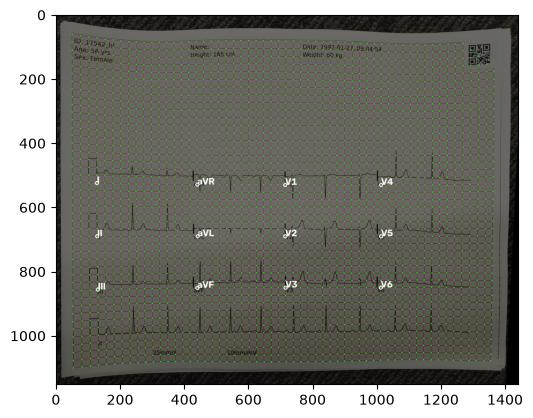

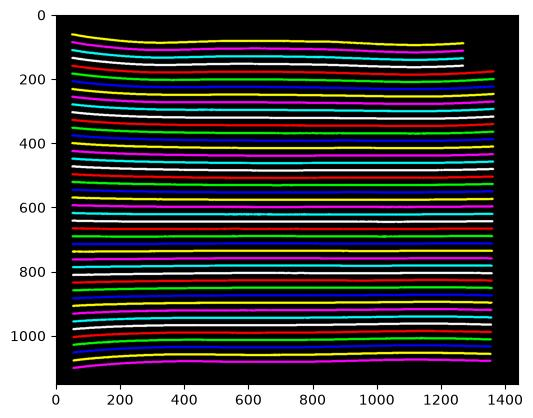

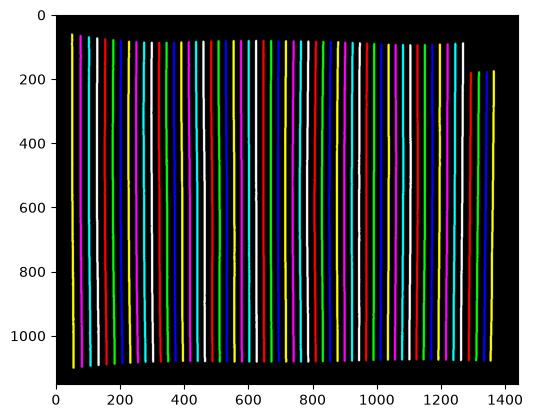

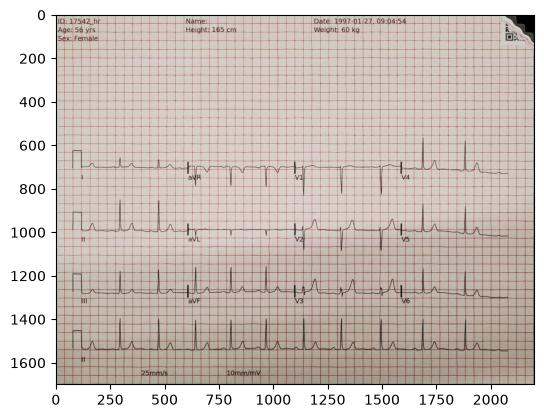

	    1 3056263433-0006  1 min 06 sec

C:\Users\darre\AppData\Local\Temp\ipykernel_45048\890628470.py:26: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.amp.autocast('cuda', dtype=FLOAT_TYPE): #torch.bfloat16



demo results for stage1--------------
3056263433-0006


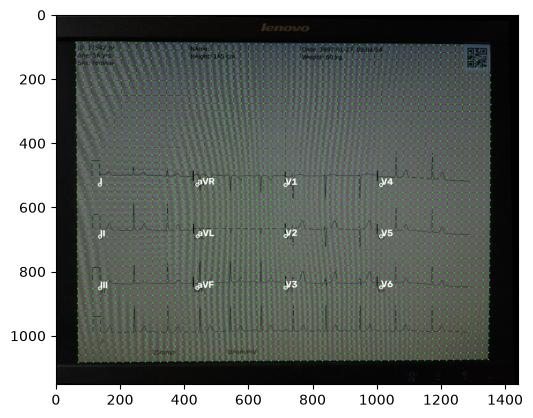

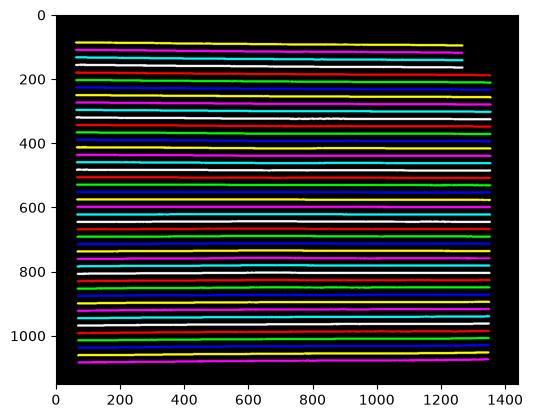

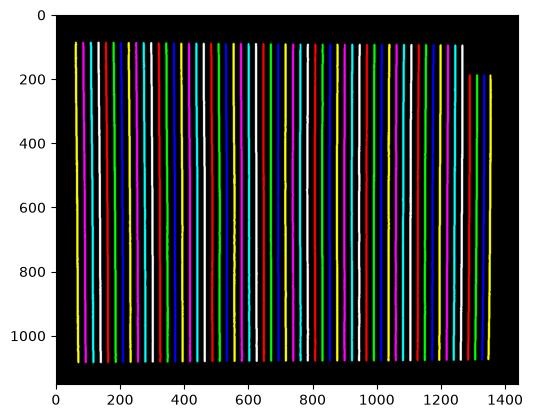

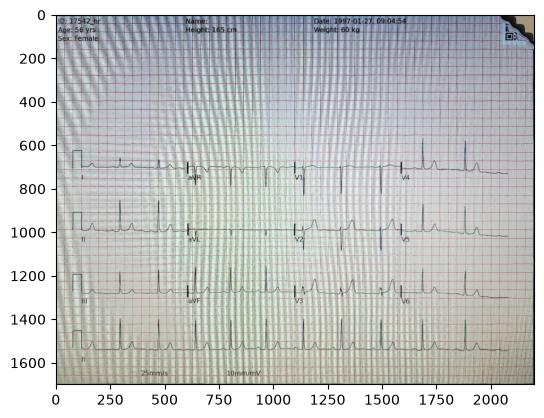

	    2 3056263433-0009  2 min 11 sec

C:\Users\darre\AppData\Local\Temp\ipykernel_45048\890628470.py:26: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.amp.autocast('cuda', dtype=FLOAT_TYPE): #torch.bfloat16



demo results for stage1--------------
3056263433-0009


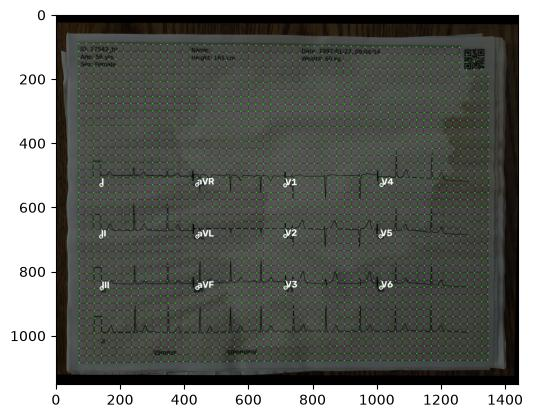

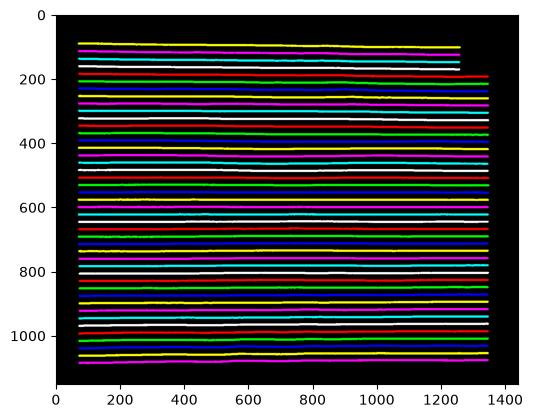

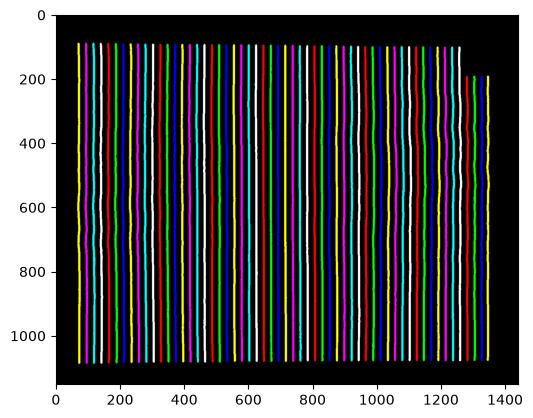

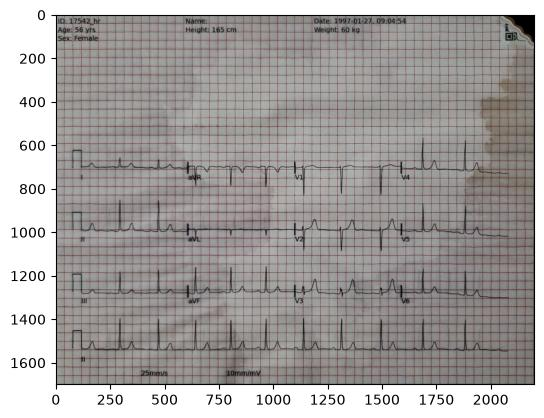


FAIL_ID: []
run_stage1() ok!!!



In [4]:
# stage1
print('*** STARTING STAGE1 ***')

from stage1_model import Net as Stage1Net
from stage1_common import *

os.makedirs(f'{OUT_DIR}/rectified', exist_ok=True)

def run_stage1():
	stage1_net = Stage1Net(pretrained=False)
	stage1_net = load_net(stage1_net, f'{WEIGHT_DIR}/stage1-last.checkpoint.pth')
	stage1_net.to(DEVICE)

	start_timer = timer()
	for n, sample_id in enumerate(valid_id):
		timestamp = time_to_str(timer() - start_timer, 'sec')
		print(f'\r\t {n:4d} {sample_id}', timestamp, end='', flush=True)
		if sample_id in FAIL_ID: continue

		image = cv2.imread(f'{OUT_DIR}/normalised/{sample_id}.norm.png', cv2.IMREAD_COLOR_RGB)
		batch = {
			'image': torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1))).unsqueeze(0),
		}
		num_tta = 1

		with torch.amp.autocast('cuda', dtype=FLOAT_TYPE): #torch.bfloat16
			with torch.no_grad():
				output = stage1_net(batch)

				try:
					gridpoint_xy, more = output_to_predict(image, batch, output)
					rectified = rectify_image(image, gridpoint_xy)
					# ---
					cv2.imwrite(f'{OUT_DIR}/rectified/{sample_id}.rect.png', cv2.cvtColor(rectified, cv2.COLOR_RGB2BGR))
					np.save(f'{OUT_DIR}/rectified/{sample_id}.gridpoint_xy.npy',gridpoint_xy)
				except:
					FAIL_ID.append(sample_id)

		torch.cuda.empty_cache()
		if n<10: # optional: show results
			overlay = draw_mapping(image, gridpoint_xy) #
			ghfiltered, gvfiltered = draw_results_stage1(more)
            
			
			print('')
			print('demo results for stage1--------------')
			print(sample_id)
			plt.imshow(overlay);plt.show()
			plt.imshow(gvfiltered);plt.show()
			plt.imshow(ghfiltered);plt.show()
			plt.imshow(rectified);plt.show()
             
	print('')

run_stage1()
print('FAIL_ID:', FAIL_ID)
print('run_stage1() ok!!!\n')

## What each stage saved

These files are the hand-off between stages. The `.rect.png` files are what the 2nd-place model is trained on.

3056263433-0005.homo.npy
3056263433-0005.norm.png
3056263433-0006.homo.npy
3056263433-0006.norm.png
3056263433-0009.homo.npy
3056263433-0009.norm.png
3056263433-0005.gridpoint_xy.npy
3056263433-0005.rect.png
3056263433-0006.gridpoint_xy.npy
3056263433-0006.rect.png
3056263433-0009.gridpoint_xy.npy
3056263433-0009.rect.png

homography (Stage 0):
 [[ 3.984000e-01  2.490000e-02 -1.683149e+02]
 [-8.100000e-03  4.228000e-01  4.821800e+00]
 [-0.000000e+00  0.000000e+00  1.000000e+00]]
grid corners (Stage 1): (44, 57, 2) -> first row of corners (x, y): [[51.0, 60.0], [77.0, 65.0], [103.0, 69.0], [129.0, 72.0]]


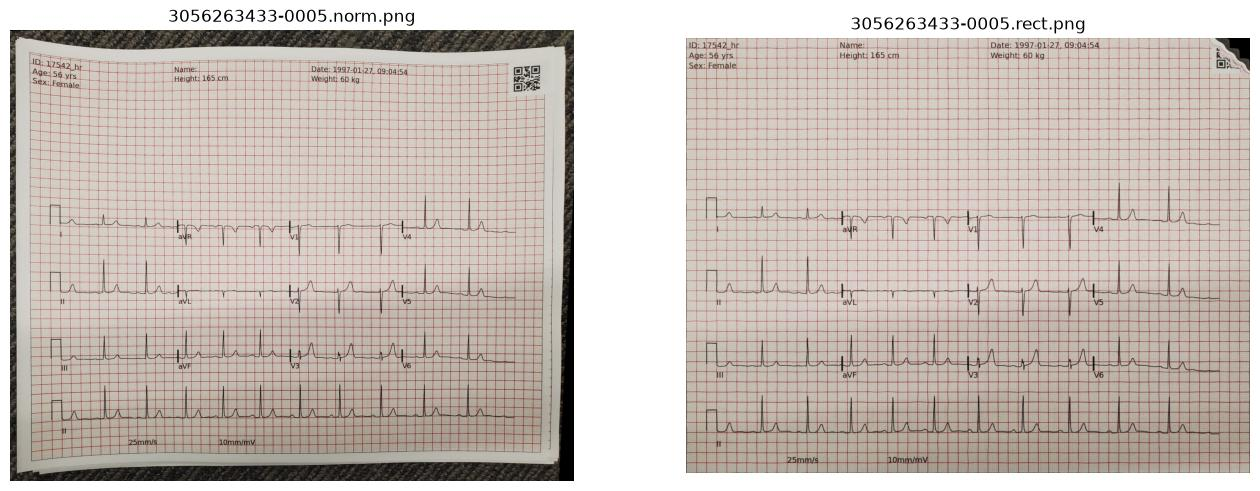

In [5]:
for f in sorted(os.listdir(OUT_DIR + '/normalised')) + sorted(os.listdir(OUT_DIR + '/rectified')):
    print(f)

sid = valid_id[0]
homo = np.load(f'{OUT_DIR}/normalised/{sid}.homo.npy')
gxy  = np.load(f'{OUT_DIR}/rectified/{sid}.gridpoint_xy.npy')
print('\nhomography (Stage 0):\n', np.round(homo, 4))
print('grid corners (Stage 1):', gxy.shape, '-> first row of corners (x, y):', np.round(gxy[0, :4], 1).tolist())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(cv2.imread(f'{OUT_DIR}/normalised/{sid}.norm.png', cv2.IMREAD_COLOR_RGB)); axes[0].set_title(f'{sid}.norm.png')
axes[1].imshow(cv2.imread(f'{OUT_DIR}/rectified/{sid}.rect.png', cv2.IMREAD_COLOR_RGB)); axes[1].set_title(f'{sid}.rect.png')
for ax in axes: ax.axis('off')
plt.show()